# Red-reference denoising of green Cellpose traces

Uses the same Cellpose masks already extracted by Suite2p in both channels. No registration, segmentation, or fluorescence extraction is repeated. The pipeline neuropil-corrects both channels, estimates a robust red-to-green noise coefficient for every ROI, subtracts zero-centred red fluctuations from green, and recalculates sliding-window ΔF/F.

## Session 216, run 04 — MY_71_R
This is a separate copy of green_cellpose_red_reference_denoising.ipynb. All input paths target session 216, run 04. Run cells in order in the mini2p-preprocessing environment. Saved output folders are specific to this workflow within that run. Existing output files in those folders are replaced when their save cells run. Trace-display ranges default to 2,000 frames where configurable; calculations use the whole recording.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import percentile_filter, binary_dilation

PLANE_DIR = Path('/Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0')
OUTPUT_DIR = PLANE_DIR / 'cellpose_red_reference_denoised'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Confirm this mapping from the two mean images below. If the channels are
# reversed, change this to 'chan2'. The other channel becomes the red reference.
GREEN_SOURCE = 'functional'  # 'functional' or 'chan2'
NEUROPIL_COEFFICIENT = 0.7
FRAME_RATE_HZ = 7.52
RED_CENTER_WINDOW_SECONDS = 30.0
DFF_BASELINE_WINDOW_SECONDS = 30.0
DFF_BASELINE_PERCENTILE = 20.0

# Robust regression settings. Coefficients are estimated from temporal
# derivatives so slow fluorescence levels and calcium baselines do not drive the fit.
REGRESSION_TRIM_PERCENTILES = (1.0, 99.0)
REGRESSION_RESIDUAL_MAD_THRESHOLD = 4.0
REGRESSION_ITERATIONS = 3
CONSTRAIN_BETA_NONNEGATIVE = True

# Discrete artifact removal from the activity-free red reference. A frame
# is interpolated only when a large red excursion occurs in many ROIs.
RED_ARTIFACT_Z_THRESHOLD = 8.0
RED_ARTIFACT_MIN_FRACTION_ROIS = 0.10
RED_ARTIFACT_PADDING_FRAMES = 1

print('Plane:', PLANE_DIR)
print('Output:', OUTPUT_DIR)


Plane: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0
Output: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0/cellpose_red_reference_denoised


## Confirm channel identity

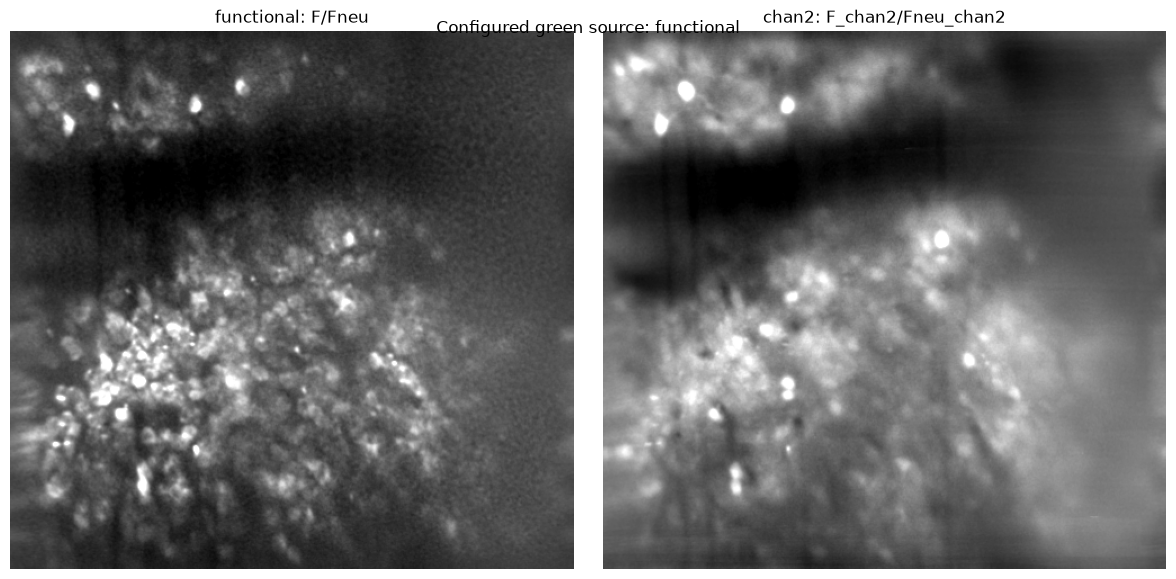

In [2]:
ops = np.load(PLANE_DIR / 'ops.npy', allow_pickle=True).item()
mean_functional = np.asarray(ops.get('meanImg'))
mean_chan2 = np.asarray(ops.get('meanImg_chan2'))
if mean_functional.ndim != 2 or mean_chan2.ndim != 2:
    raise KeyError('ops.npy must contain both meanImg and meanImg_chan2')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, image, title in zip(
    axes, [mean_functional, mean_chan2], ['functional: F/Fneu', 'chan2: F_chan2/Fneu_chan2']
):
    lo, hi = np.percentile(image[np.isfinite(image)], [1, 99.5])
    ax.imshow(image, cmap='gray', vmin=lo, vmax=hi)
    ax.set_title(title)
    ax.axis('off')
fig.suptitle(f'Configured green source: {GREEN_SOURCE}', y=0.94)
fig.tight_layout()
plt.show()


## Load existing Suite2p traces and neuropil-correct both channels

In [3]:
F_functional = np.load(PLANE_DIR / 'F.npy').astype(np.float32)
Fneu_functional = np.load(PLANE_DIR / 'Fneu.npy').astype(np.float32)
F_chan2 = np.load(PLANE_DIR / 'F_chan2.npy').astype(np.float32)
Fneu_chan2 = np.load(PLANE_DIR / 'Fneu_chan2.npy').astype(np.float32)
stat = np.load(PLANE_DIR / 'stat.npy', allow_pickle=True)
iscell = np.load(PLANE_DIR / 'iscell.npy')

shapes = {x.shape for x in [F_functional, Fneu_functional, F_chan2, Fneu_chan2]}
if len(shapes) != 1:
    raise ValueError(f'Channel trace shapes do not agree: {shapes}')
if F_functional.shape[0] != len(stat):
    raise ValueError('Trace count does not match stat.npy')

if GREEN_SOURCE == 'functional':
    F_green_cell, F_green_neuropil = F_functional, Fneu_functional
    F_red_cell, F_red_neuropil = F_chan2, Fneu_chan2
elif GREEN_SOURCE == 'chan2':
    F_green_cell, F_green_neuropil = F_chan2, Fneu_chan2
    F_red_cell, F_red_neuropil = F_functional, Fneu_functional
else:
    raise ValueError("GREEN_SOURCE must be 'functional' or 'chan2'")

F_green_corrected = (F_green_cell - NEUROPIL_COEFFICIENT * F_green_neuropil).astype(np.float32)
F_red_corrected = (F_red_cell - NEUROPIL_COEFFICIENT * F_red_neuropil).astype(np.float32)
print('ROIs × frames:', F_green_corrected.shape)
print('Green source:', GREEN_SOURCE)
print('Red reference:', 'chan2' if GREEN_SOURCE == 'functional' else 'functional')


ROIs × frames: (400, 8503)
Green source: functional
Red reference: chan2


## Build the red reference and estimate robust per-ROI coefficients

In [4]:
red_center_window_frames = int(round(FRAME_RATE_HZ * RED_CENTER_WINDOW_SECONDS))
if red_center_window_frames < 1:
    raise ValueError('Red centering window must contain at least one frame')

# Remove only the slow red baseline. The remaining red fluctuations are the
# reference signal used for noise regression.
F_red_slow = percentile_filter(
    F_red_corrected, percentile=50, size=(1, red_center_window_frames), mode='nearest'
)
red_reference = (F_red_corrected - F_red_slow).astype(np.float32)

def robust_derivative_beta(green_trace, red_trace, trim=(1, 99), mad_threshold=4, iterations=3):
    dg = np.diff(np.asarray(green_trace, dtype=np.float64))
    dr = np.diff(np.asarray(red_trace, dtype=np.float64))
    valid = np.isfinite(dg) & np.isfinite(dr)
    if valid.sum() < 10:
        return np.nan, int(valid.sum())
    dg_lo, dg_hi = np.percentile(dg[valid], trim)
    dr_lo, dr_hi = np.percentile(dr[valid], trim)
    keep = valid & (dg >= dg_lo) & (dg <= dg_hi) & (dr >= dr_lo) & (dr <= dr_hi)
    beta = np.nan
    for _ in range(iterations):
        if keep.sum() < 10:
            break
        x = dr[keep] - np.median(dr[keep])
        y = dg[keep] - np.median(dg[keep])
        denominator = np.dot(x, x)
        if denominator <= 1e-12:
            break
        beta = np.dot(x, y) / denominator
        residual = dg - beta * dr
        residual_center = np.median(residual[keep])
        residual_mad = np.median(np.abs(residual[keep] - residual_center))
        residual_scale = 1.4826 * residual_mad
        if not np.isfinite(residual_scale) or residual_scale <= 1e-12:
            break
        keep &= np.abs(residual - residual_center) <= mad_threshold * residual_scale
    return beta, int(keep.sum())

red_beta = np.full(F_green_corrected.shape[0], np.nan, dtype=np.float32)
regression_sample_count = np.zeros(F_green_corrected.shape[0], dtype=int)
for roi in range(F_green_corrected.shape[0]):
    beta, count = robust_derivative_beta(
        F_green_corrected[roi], red_reference[roi],
        trim=REGRESSION_TRIM_PERCENTILES,
        mad_threshold=REGRESSION_RESIDUAL_MAD_THRESHOLD,
        iterations=REGRESSION_ITERATIONS,
    )
    red_beta[roi] = beta
    regression_sample_count[roi] = count

if CONSTRAIN_BETA_NONNEGATIVE:
    red_beta = np.maximum(red_beta, 0)
valid_beta = np.isfinite(red_beta)
print(f'Valid regression coefficients: {valid_beta.sum()} / {len(red_beta)}')
print('Beta median and 1st–99th percentiles:', np.nanmedian(red_beta), np.nanpercentile(red_beta, [1, 99]))


Valid regression coefficients: 400 / 400
Beta median and 1st–99th percentiles: 0.04244277 [0.         0.11845689]


## Regress red fluctuations from green and calculate sliding ΔF/F

In [5]:
F_green_denoised = np.full_like(F_green_corrected, np.nan)
F_green_denoised[valid_beta] = (
    F_green_corrected[valid_beta]
    - red_beta[valid_beta, None] * red_reference[valid_beta]
).astype(np.float32)

# Detect discrete artifacts from red amplitude, independently for each ROI,
# then require simultaneous excursions across a population of ROIs.
red_median = np.nanmedian(red_reference, axis=1, keepdims=True)
red_mad = np.nanmedian(np.abs(red_reference - red_median), axis=1, keepdims=True)
red_scale = 1.4826 * red_mad
red_scale[red_scale < 1e-12] = np.nan
red_amplitude_z = (red_reference - red_median) / red_scale
valid_red_rois = np.any(np.isfinite(red_amplitude_z), axis=1)
red_fraction_artifact = np.mean(
    np.abs(red_amplitude_z[valid_red_rois]) >= RED_ARTIFACT_Z_THRESHOLD, axis=0
)
red_artifact_frames = red_fraction_artifact >= RED_ARTIFACT_MIN_FRACTION_ROIS
if RED_ARTIFACT_PADDING_FRAMES > 0:
    red_artifact_frames = binary_dilation(
        red_artifact_frames,
        structure=np.ones(2 * RED_ARTIFACT_PADDING_FRAMES + 1, dtype=bool),
    )

# Interpolate the regression-corrected green signal across only the frames
# independently identified as artifacts in red.
F_green_clean = F_green_denoised.copy()
frame_numbers = np.arange(F_green_clean.shape[1])
for roi in range(F_green_clean.shape[0]):
    valid = ~red_artifact_frames & np.isfinite(F_green_denoised[roi])
    if valid.sum() >= 2:
        F_green_clean[roi, red_artifact_frames] = np.interp(
            frame_numbers[red_artifact_frames], frame_numbers[valid],
            F_green_denoised[roi, valid],
        )
print(
    f'Red-identified artifact frames after ±{RED_ARTIFACT_PADDING_FRAMES} padding: '
    f'{red_artifact_frames.sum()} / {len(red_artifact_frames)} '
    f'({100 * red_artifact_frames.mean():.3f}%)'
)

baseline_window_frames = int(round(FRAME_RATE_HZ * DFF_BASELINE_WINDOW_SECONDS))
if baseline_window_frames < 1:
    raise ValueError('ΔF/F baseline window must contain at least one frame')
F0 = percentile_filter(
    F_green_clean, percentile=DFF_BASELINE_PERCENTILE,
    size=(1, baseline_window_frames), mode='nearest',
)
valid_baseline = np.isfinite(F0) & (F0 > 1e-6)
dff = np.full_like(F_green_clean, np.nan)
np.divide(F_green_clean - F0, F0, out=dff, where=valid_baseline)
valid_roi_indices = np.flatnonzero(np.any(np.isfinite(dff), axis=1))
invalid_roi_indices = np.setdiff1d(np.arange(dff.shape[0]), valid_roi_indices)
print(f'Valid ΔF/F ROIs: {len(valid_roi_indices)} / {dff.shape[0]}')
print('Excluded ROI IDs:', invalid_roi_indices.tolist())
print('Finite ΔF/F range:', np.nanmin(dff), np.nanmax(dff))


Red-identified artifact frames after ±1 padding: 1032 / 8503 (12.137%)
Valid ΔF/F ROIs: 400 / 400
Excluded ROI IDs: []
Finite ΔF/F range: -57310.043 122871.45


## Regression diagnostics

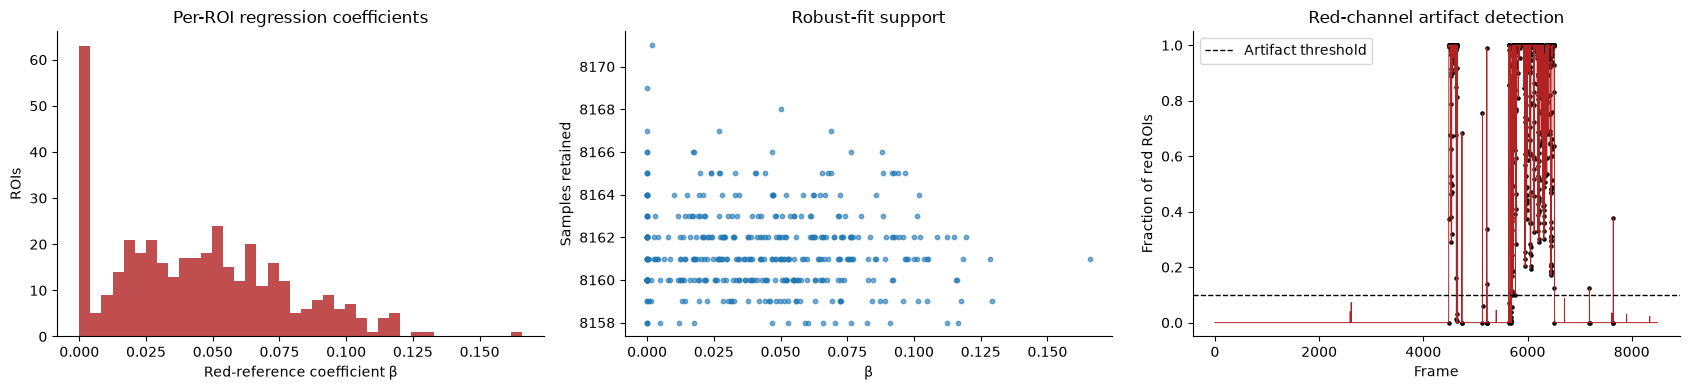

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].hist(red_beta[valid_beta], bins=40, color='firebrick', alpha=0.8)
axes[0].set(xlabel='Red-reference coefficient β', ylabel='ROIs', title='Per-ROI regression coefficients')
axes[1].scatter(red_beta[valid_beta], regression_sample_count[valid_beta], s=10, alpha=0.6)
axes[1].set(xlabel='β', ylabel='Samples retained', title='Robust-fit support')
axes[2].plot(red_fraction_artifact, lw=0.7, color='firebrick')
axes[2].axhline(
    RED_ARTIFACT_MIN_FRACTION_ROIS, color='black', ls='--', lw=1,
    label='Artifact threshold',
)
axes[2].scatter(
    np.flatnonzero(red_artifact_frames),
    red_fraction_artifact[red_artifact_frames], s=5, color='black',
)
axes[2].set(
    xlabel='Frame', ylabel='Fraction of red ROIs',
    title='Red-channel artifact detection',
)
axes[2].legend()
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()


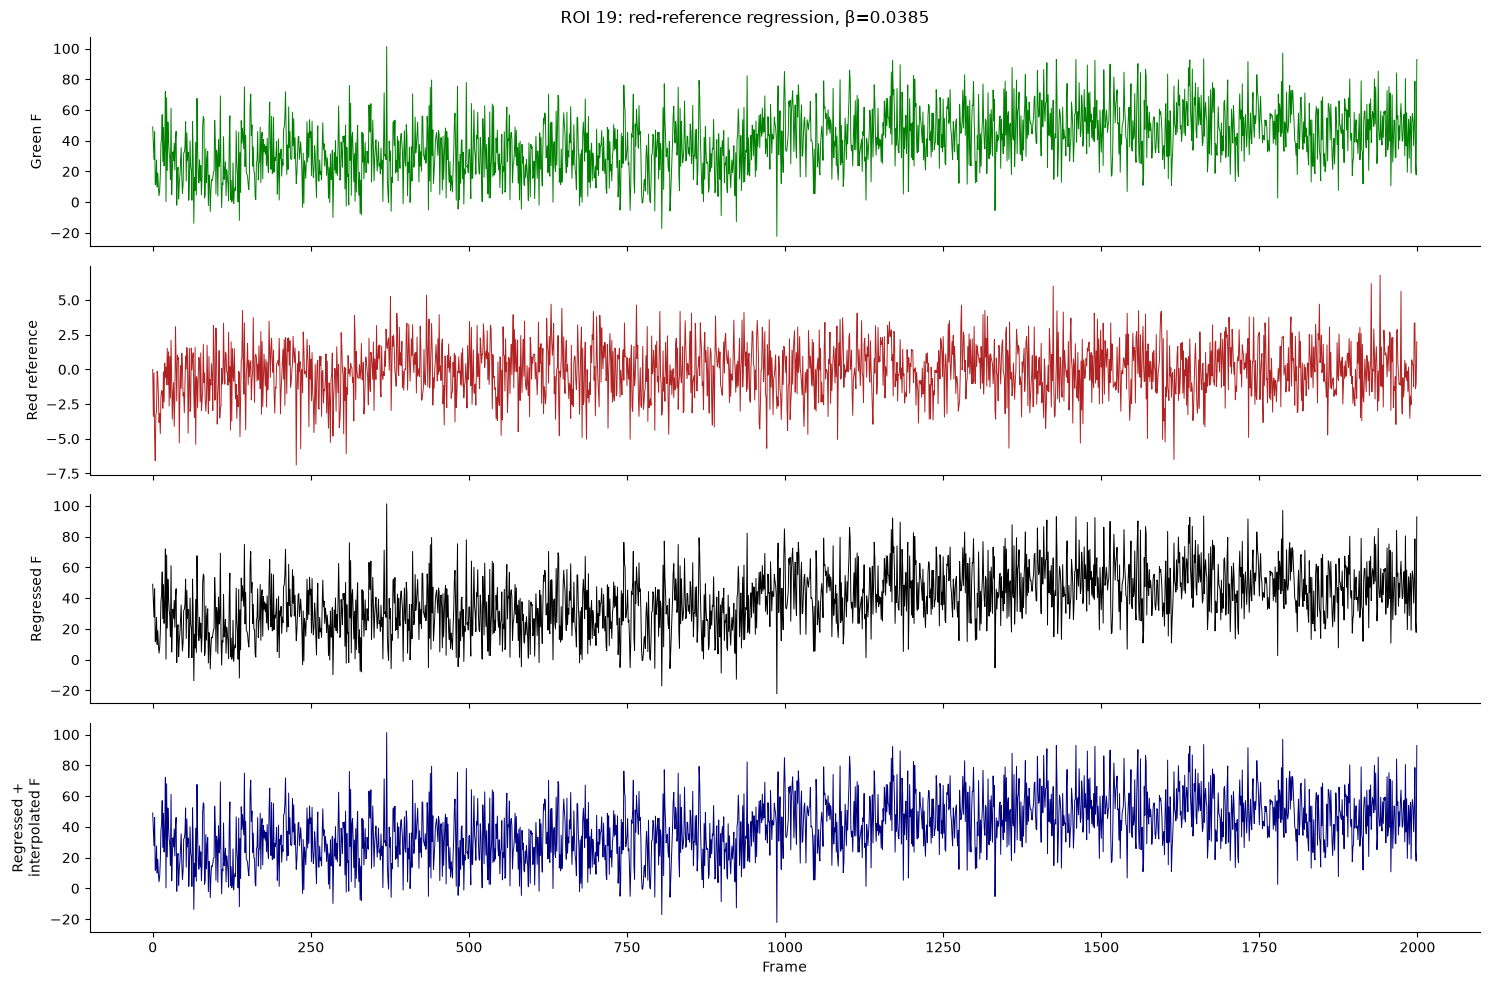

In [7]:
EXAMPLE_ROI = int(valid_roi_indices[19])
EXAMPLE_START_FRAME = 0
EXAMPLE_END_FRAME = 2000
sl = slice(EXAMPLE_START_FRAME, EXAMPLE_END_FRAME)
frames = np.arange(F_green_corrected.shape[1])[sl]
fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
axes[0].plot(frames, F_green_corrected[EXAMPLE_ROI, sl], lw=0.7, color='green')
axes[0].set_ylabel('Green F')
axes[1].plot(frames, red_reference[EXAMPLE_ROI, sl], lw=0.7, color='firebrick')
axes[1].set_ylabel('Red reference')
axes[2].plot(frames, F_green_denoised[EXAMPLE_ROI, sl], lw=0.7, color='black')
axes[2].set_ylabel('Regressed F')
axes[3].plot(frames, F_green_clean[EXAMPLE_ROI, sl], lw=0.7, color='navy')
artifact_in_view = np.flatnonzero(red_artifact_frames[sl]) + EXAMPLE_START_FRAME
for artifact_frame in artifact_in_view:
    axes[1].axvline(artifact_frame, color='0.5', alpha=0.2, lw=0.6)
axes[3].set_ylabel('Regressed +\ninterpolated F')
axes[3].set_xlabel('Frame')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'ROI {EXAMPLE_ROI}: red-reference regression, β={red_beta[EXAMPLE_ROI]:.3g}')
fig.tight_layout()
plt.show()


## Plot denoised ΔF/F traces

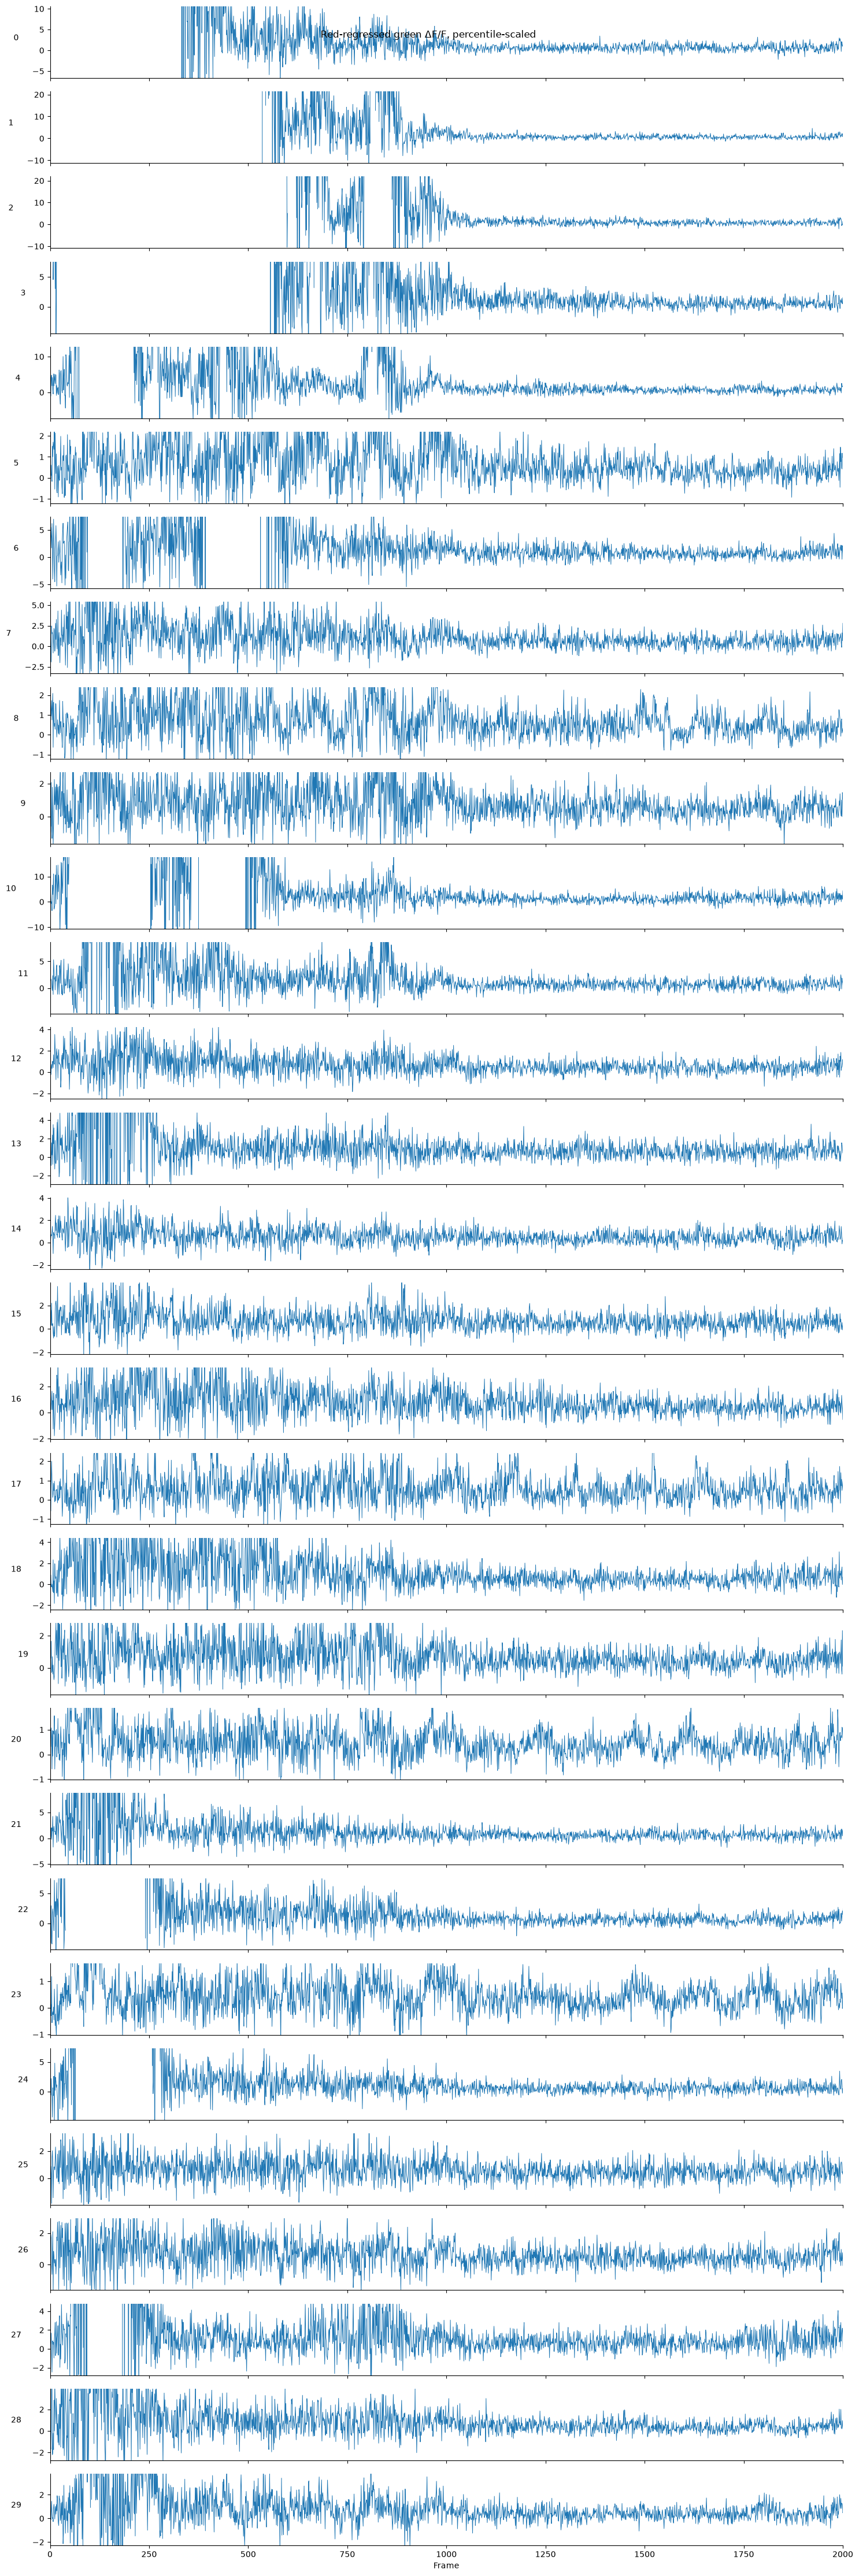

In [8]:
N_ROIS_TO_PLOT = 30
PLOT_START_FRAME = 0
PLOT_END_FRAME = 2000
PLOT_PERCENTILES = (1.0, 95.0)
rois_to_plot = valid_roi_indices[:N_ROIS_TO_PLOT]
fig, axes = plt.subplots(len(rois_to_plot), 1, figsize=(15, 1.5 * len(rois_to_plot)), sharex=True)
axes = np.atleast_1d(axes)
for ax, roi in zip(axes, rois_to_plot):
    trace = dff[roi]
    ax.plot(trace, lw=0.7)
    lo, hi = np.nanpercentile(trace, PLOT_PERCENTILES)
    pad = 0.1 * (hi - lo) if hi > lo else 1.0
    ax.set_ylim(lo - pad, hi + pad)
    ax.set_xlim(PLOT_START_FRAME, PLOT_END_FRAME)
    ax.set_ylabel(str(roi), rotation=0, labelpad=20)
    ax.spines[['top', 'right']].set_visible(False)
axes[-1].set_xlabel('Frame')
fig.suptitle('Red-regressed green ΔF/F, percentile-scaled')
fig.tight_layout()
plt.show()


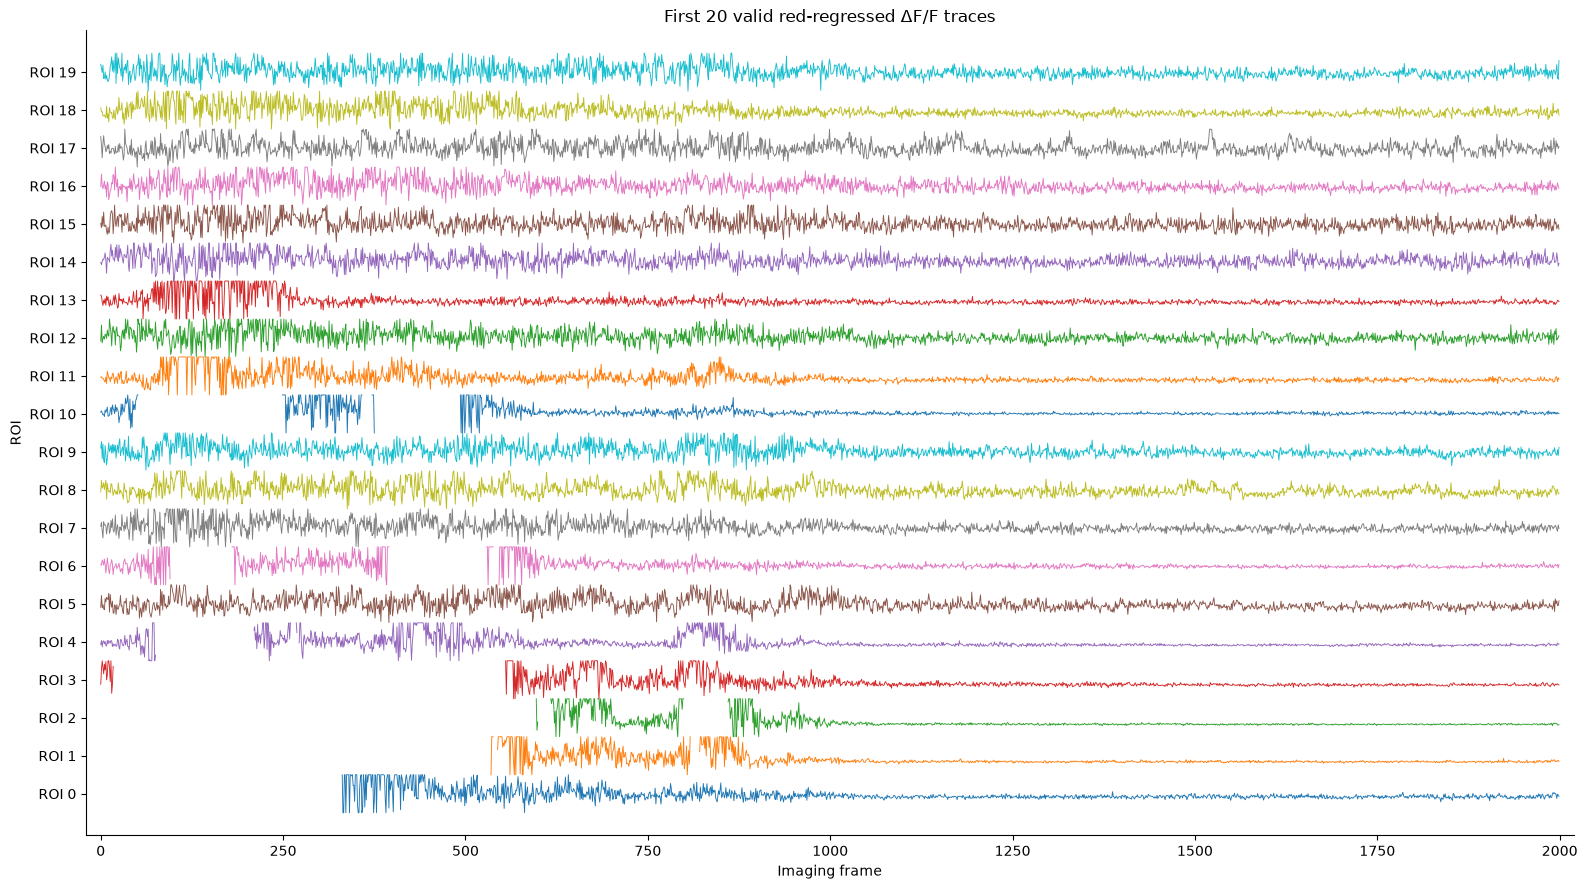

In [9]:
N_STACKED_ROIS = 20
STACKED_START_FRAME = 0
STACKED_END_FRAME = 2000
STACK_SPACING = 1.5
stacked_rois = valid_roi_indices[:N_STACKED_ROIS]
sl = slice(STACKED_START_FRAME, STACKED_END_FRAME)
frames = np.arange(dff.shape[1])[sl]
offsets = np.arange(len(stacked_rois)) * STACK_SPACING
colors = plt.cm.tab10(np.arange(len(stacked_rois)) % 10)
fig, ax = plt.subplots(figsize=(16, max(6, 0.45 * len(stacked_rois))))
for offset, color, roi in zip(offsets, colors, stacked_rois):
    trace = np.asarray(dff[roi, sl], dtype=float)
    lo, hi = np.nanpercentile(trace, PLOT_PERCENTILES)
    if not np.isfinite(hi - lo) or hi <= lo:
        continue
    shown = np.clip((trace - lo) / (hi - lo), -0.25, 1.25)
    ax.plot(frames, shown + offset, color=color, lw=0.65)
ax.set_yticks(offsets + 0.5, [f'ROI {roi}' for roi in stacked_rois])
ax.set(xlabel='Imaging frame', ylabel='ROI', title=f'First {len(stacked_rois)} valid red-regressed ΔF/F traces')
ax.spines[['top', 'right']].set_visible(False)
ax.margins(x=0.01, y=0.03)
fig.tight_layout()
plt.show()


## Save outputs for behavior alignment

In [10]:
np.save(OUTPUT_DIR / 'F.npy', F_green_clean)
np.save(OUTPUT_DIR / 'F0.npy', F0)
np.save(OUTPUT_DIR / 'dff.npy', dff)
np.save(OUTPUT_DIR / 'F_green_cell.npy', F_green_cell)
np.save(OUTPUT_DIR / 'F_green_neuropil.npy', F_green_neuropil)
np.save(OUTPUT_DIR / 'F_green_corrected.npy', F_green_corrected)
np.save(OUTPUT_DIR / 'F_green_regressed.npy', F_green_denoised)
np.save(OUTPUT_DIR / 'F_green_clean.npy', F_green_clean)
np.save(OUTPUT_DIR / 'F_red_cell.npy', F_red_cell)
np.save(OUTPUT_DIR / 'F_red_neuropil.npy', F_red_neuropil)
np.save(OUTPUT_DIR / 'F_red_corrected.npy', F_red_corrected)
np.save(OUTPUT_DIR / 'red_reference.npy', red_reference)
np.save(OUTPUT_DIR / 'red_beta.npy', red_beta)
np.save(OUTPUT_DIR / 'red_artifact_frames.npy', red_artifact_frames)
np.save(OUTPUT_DIR / 'red_fraction_artifact.npy', red_fraction_artifact)
np.save(OUTPUT_DIR / 'regression_sample_count.npy', regression_sample_count)
np.save(OUTPUT_DIR / 'valid_dff_rois.npy', np.any(np.isfinite(dff), axis=1))
np.save(OUTPUT_DIR / 'stat.npy', stat)
np.save(OUTPUT_DIR / 'iscell.npy', iscell)
print('Saved behavior-ready outputs to:', OUTPUT_DIR)
print('Set TRACE_DIR in align_behavior_and_plot_reward_dff.ipynb to this directory.')


Saved behavior-ready outputs to: /Volumes/behrens/meg/3x3_field_magnitude_bandit/derivatives/cohort-01/sub-03_id-MY_71_R/ses-216_date-20260730/funcimg/run-04/suite2p/plane0/cellpose_red_reference_denoised
Set TRACE_DIR in align_behavior_and_plot_reward_dff.ipynb to this directory.
